# Experiment 6: Fuzzy Logic and Constraint Satisfaction

## Imports

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1: Fuzzy Logic System - Student Performance

### Membership Functions

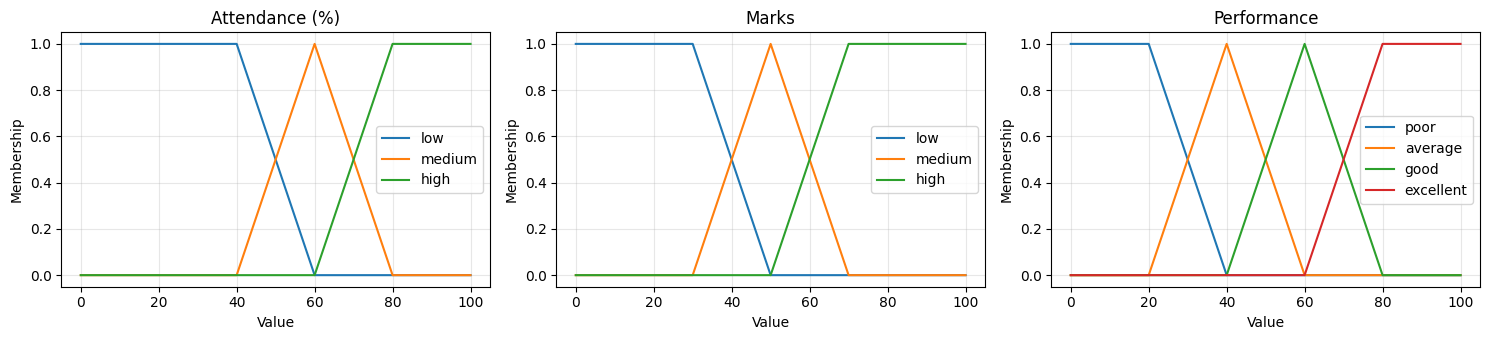

In [2]:
def trapmf(x, abcd):
    """Trapezoidal membership function (a == b or c == d gives a flat shoulder)."""
    a, b, c, d = abcd
    x = np.asarray(x, dtype=float)
    up = np.ones_like(x) if b == a else np.clip((x - a) / (b - a), 0, 1)
    down = np.ones_like(x) if d == c else np.clip((d - x) / (d - c), 0, 1)
    return np.minimum(up, down)


def trimf(x, abc):
    """Triangular membership function."""
    a, b, c = abc
    return trapmf(x, (a, b, b, c))


# Common universe (0-100) used for attendance, marks and performance
x_perf = np.linspace(0, 100, 1001)

attendance_mf = {
    "low":    lambda x: trapmf(x, (0, 0, 40, 60)),
    "medium": lambda x: trimf(x, (40, 60, 80)),
    "high":   lambda x: trapmf(x, (60, 80, 100, 100)),
}

marks_mf = {
    "low":    lambda x: trapmf(x, (0, 0, 30, 50)),
    "medium": lambda x: trimf(x, (30, 50, 70)),
    "high":   lambda x: trapmf(x, (50, 70, 100, 100)),
}

performance_mf = {
    "poor":      lambda x: trapmf(x, (0, 0, 20, 40)),
    "average":   lambda x: trimf(x, (20, 40, 60)),
    "good":      lambda x: trimf(x, (40, 60, 80)),
    "excellent": lambda x: trapmf(x, (60, 80, 100, 100)),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (title, mfs) in zip(axes, [("Attendance (%)", attendance_mf),
                                   ("Marks", marks_mf),
                                   ("Performance", performance_mf)]):
    for name, mf in mfs.items():
        ax.plot(x_perf, mf(x_perf), label=name)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Membership")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fuzzy Rules

In [3]:
# (attendance term, marks term) -> performance term
rules = {
    ("low", "low"):       "poor",
    ("low", "medium"):    "poor",
    ("low", "high"):      "average",
    ("medium", "low"):    "poor",
    ("medium", "medium"): "average",
    ("medium", "high"):   "good",
    ("high", "low"):      "average",
    ("high", "medium"):   "good",
    ("high", "high"):     "excellent",
}

print("Fuzzy rules:")
for (a, m), out in rules.items():
    print(f"  IF attendance is {a} AND marks are {m} THEN performance is {out}")

Fuzzy rules:
  IF attendance is low AND marks are low THEN performance is poor
  IF attendance is low AND marks are medium THEN performance is poor
  IF attendance is low AND marks are high THEN performance is average
  IF attendance is medium AND marks are low THEN performance is poor
  IF attendance is medium AND marks are medium THEN performance is average
  IF attendance is medium AND marks are high THEN performance is good
  IF attendance is high AND marks are low THEN performance is average
  IF attendance is high AND marks are medium THEN performance is good
  IF attendance is high AND marks are high THEN performance is excellent


### Inference and Defuzzification

In [4]:
def fuzzify(value, mfs):
    return {name: float(mf(value)) for name, mf in mfs.items()}


def fuzzy_eval(attendance, marks, rule_set, return_details=False):
    """Mamdani inference: AND = min, implication = clip, aggregation = max, centroid output."""
    mu_att = fuzzify(attendance, attendance_mf)
    mu_mark = fuzzify(marks, marks_mf)

    aggregated = np.zeros_like(x_perf)
    for (a_term, m_term), out_term in rule_set.items():
        strength = min(mu_att[a_term], mu_mark[m_term])
        clipped = np.minimum(strength, performance_mf[out_term](x_perf))
        aggregated = np.maximum(aggregated, clipped)

    area = aggregated.sum()
    score = float((x_perf * aggregated).sum() / area) if area > 0 else 0.0
    if return_details:
        return score, aggregated
    return score


def label(score):
    """Linguistic label with the highest membership for a crisp score."""
    return max(performance_mf, key=lambda k: float(performance_mf[k](score)))

### Test Cases

In [5]:
tests = [(95, 90), (90, 40), (30, 85), (60, 60), (45, 35), (20, 20), (100, 100), (75, 65)]

print(f"{'Attendance':>10} {'Marks':>7} {'Score':>8}  Label")
for att, mk in tests:
    s = fuzzy_eval(att, mk, rules)
    print(f"{att:>10} {mk:>7} {s:>8.2f}  {label(s)}")

Attendance   Marks    Score  Label
        95      90    84.47  excellent
        90      40    50.00  average
        30      85    40.00  average
        60      60    50.00  average
        45      35    21.78  poor
        20      20    15.53  poor
       100     100    84.47  excellent
        75      65    71.58  excellent


### Aggregated Output for One Input

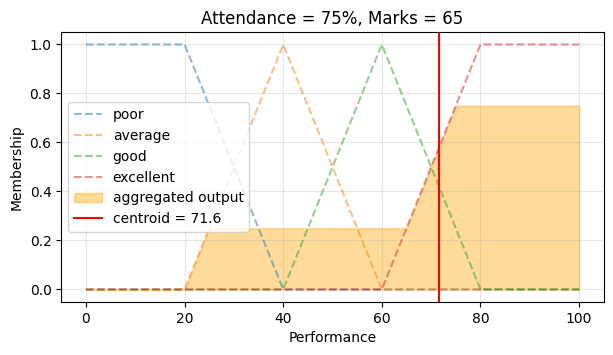

Performance score = 71.58 (excellent)


In [6]:
att, mk = 75, 65
score, agg = fuzzy_eval(att, mk, rules, return_details=True)

plt.figure(figsize=(7, 3.5))
for name, mf in performance_mf.items():
    plt.plot(x_perf, mf(x_perf), "--", alpha=0.5, label=name)
plt.fill_between(x_perf, agg, alpha=0.4, color="orange", label="aggregated output")
plt.axvline(score, color="red", label=f"centroid = {score:.1f}")
plt.title(f"Attendance = {att}%, Marks = {mk}")
plt.xlabel("Performance")
plt.ylabel("Membership")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Performance score = {score:.2f} ({label(score)})")

### Output for Different Attendance and Marks

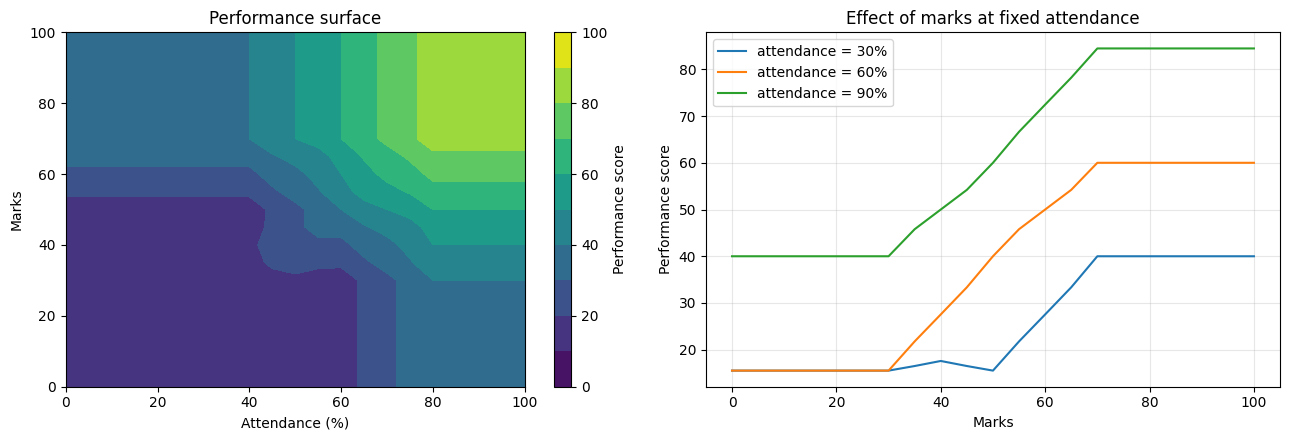

In [7]:
grid = np.arange(0, 101, 5)


def surface(rule_set):
    # rows -> marks, columns -> attendance
    return np.array([[fuzzy_eval(a, m, rule_set) for a in grid] for m in grid])


Z = surface(rules)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cs = axes[0].contourf(grid, grid, Z, levels=np.linspace(0, 100, 11), cmap="viridis")
fig.colorbar(cs, ax=axes[0], label="Performance score")
axes[0].set(xlabel="Attendance (%)", ylabel="Marks", title="Performance surface")

for att in (30, 60, 90):
    axes[1].plot(grid, [fuzzy_eval(att, m, rules) for m in grid], label=f"attendance = {att}%")
axes[1].set(xlabel="Marks", ylabel="Performance score", title="Effect of marks at fixed attendance")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Exercise 2: Timetable Problem (CSP)

### Variables, Domains and Constraints

In [ ]:
courses = ["Maths", "Physics", "Chemistry", "CS", "English"]          # variables
SLOTS = [("Mon", 9), ("Mon", 10), ("Mon", 14),
         ("Tue", 9), ("Tue", 10), ("Tue", 14)]                          # possible time slots
domains = {c: list(SLOTS) for c in courses}


def base_constraints():
    """Each constraint = (description, tuple of variables, function of their values)."""
    cons = []
    # One classroom: no two courses share a slot
    for a, b in itertools.combinations(courses, 2):
        cons.append((f"{a} and {b} not in the same slot", (a, b), lambda x, y: x != y))
    cons += [
        ("Maths in the morning",
         ("Maths",), lambda s: s[1] < 12),
        ("Chemistry lab in the afternoon",
         ("Chemistry",), lambda s: s[1] >= 12),
        ("English not on Tuesday",
         ("English",), lambda s: s[0] != "Tue"),
        ("Physics and Chemistry on different days",
         ("Physics", "Chemistry"), lambda p, c: p[0] != c[0]),
        ("CS scheduled after Maths",
         ("CS", "Maths"), lambda cs, m: SLOTS.index(cs) > SLOTS.index(m)),
    ]
    return cons


constraints = base_constraints()

print("Variables (courses):", courses)
print("Domain (time slots):", [f"{d} {h}:00" for d, h in SLOTS])
print(f"\nConstraints ({len(constraints)}):")
for name, _, _ in constraints:
    print("  -", name)

Variables (courses): ['Maths', 'Physics', 'Chemistry', 'CS', 'English']
Domain (time slots): ['Mon 9:00', 'Mon 10:00', 'Mon 14:00', 'Tue 9:00', 'Tue 10:00', 'Tue 14:00']

Constraints (15):
  - Maths and Physics not in the same slot
  - Maths and Chemistry not in the same slot
  - Maths and CS not in the same slot
  - Maths and English not in the same slot
  - Physics and Chemistry not in the same slot
  - Physics and CS not in the same slot
  - Physics and English not in the same slot
  - Chemistry and CS not in the same slot
  - Chemistry and English not in the same slot
  - CS and English not in the same slot
  - Maths in the morning
  - Chemistry lab in the afternoon
  - English not on Tuesday
  - Physics and Chemistry on different days
  - CS scheduled after Maths


### Backtracking Solver

In [9]:
def consistent(assignment, cons):
    """True if every constraint whose variables are all assigned is satisfied."""
    for _, scope, fn in cons:
        if all(v in assignment for v in scope):
            if not fn(*(assignment[v] for v in scope)):
                return False
    return True


def solve(variables, doms, cons):
    """Generator yielding every complete assignment that satisfies all constraints."""
    def backtrack(assignment):
        if len(assignment) == len(variables):
            yield dict(assignment)
            return
        var = next(v for v in variables if v not in assignment)
        for value in doms[var]:
            assignment[var] = value
            if consistent(assignment, cons):
                yield from backtrack(assignment)
            del assignment[var]

    return backtrack({})


def show_timetable(solution):
    days = ["Mon", "Tue"]
    hours = [9, 10, 14]
    by_slot = {slot: course for course, slot in solution.items()}
    print(f"{'Time':<8}" + "".join(f"{d:<12}" for d in days))
    print("-" * (8 + 12 * len(days)))
    for h in hours:
        row = "".join(f"{by_slot.get((d, h), '-'):<12}" for d in days)
        print(f"{str(h) + ':00':<8}{row}")

### Generated Timetable

In [10]:
solutions = list(solve(courses, domains, constraints))
print("Total valid timetables:", len(solutions))

if solutions:
    first = solutions[0]
    print("\nFirst valid timetable:\n")
    show_timetable(first)

    print("\nAssignment:")
    for course, (d, h) in sorted(first.items(), key=lambda kv: SLOTS.index(kv[1])):
        print(f"  {course:<10} -> {d} {h}:00")

    ok = all(fn(*(first[v] for v in scope)) for _, scope, fn in constraints)
    print("\nAll constraints satisfied:", ok)
else:
    print("No timetable satisfies all constraints.")

Total valid timetables: 32

First valid timetable:

Time    Mon         Tue         
--------------------------------
9:00    Maths       CS          
10:00   Physics     -           
14:00   English     Chemistry   

Assignment:
  Maths      -> Mon 9:00
  Physics    -> Mon 10:00
  English    -> Mon 14:00
  CS         -> Tue 9:00
  Chemistry  -> Tue 14:00

All constraints satisfied: True


## Exercise 3: Changing Rules and Constraints

### Modified Fuzzy Rules

In [11]:
# Strict on attendance: poor attendance (or poor marks with good attendance) is penalised more
rules_strict = dict(rules)
rules_strict[("low", "high")] = "poor"
rules_strict[("high", "low")] = "poor"
rules_strict[("medium", "high")] = "average"

# Marks-focused: high marks are rewarded even when attendance is weak
rules_marks_focus = dict(rules)
rules_marks_focus[("low", "high")] = "good"
rules_marks_focus[("medium", "high")] = "excellent"
rules_marks_focus[("high", "low")] = "poor"


def show_changes(name, new_rules):
    print(f"{name} - changed rules:")
    for key in rules:
        if rules[key] != new_rules[key]:
            print(f"  attendance={key[0]}, marks={key[1]}: {rules[key]} -> {new_rules[key]}")
    print()


show_changes("Strict rules", rules_strict)
show_changes("Marks-focused rules", rules_marks_focus)

Strict rules - changed rules:
  attendance=low, marks=high: average -> poor
  attendance=medium, marks=high: good -> average
  attendance=high, marks=low: average -> poor

Marks-focused rules - changed rules:
  attendance=low, marks=high: average -> good
  attendance=medium, marks=high: good -> excellent
  attendance=high, marks=low: average -> poor



### Effect on Fuzzy Output

Attendance  Marks |      Original |        Strict | Marks-focused
        95     90 |         84.47 |         84.47 |         84.47
        90     40 |         50.00 |         37.15 |         37.15
        30     85 |         40.00 |         15.53 |         60.00
        60     60 |         50.00 |         40.00 |         62.85
        45     35 |         21.78 |         21.78 |         21.78
        20     20 |         15.53 |         15.53 |         15.53
       100    100 |         84.47 |         84.47 |         84.47
        75     65 |         71.58 |         71.58 |         71.58


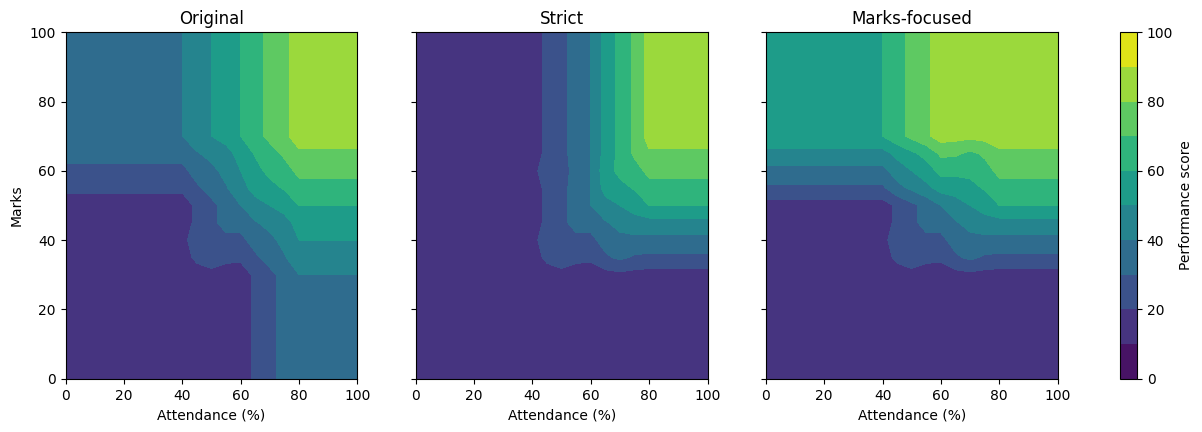

In [12]:
rule_sets = {"Original": rules, "Strict": rules_strict, "Marks-focused": rules_marks_focus}

print(f"{'Attendance':>10} {'Marks':>6} | " + " | ".join(f"{n:>13}" for n in rule_sets))
for att, mk in tests:
    row = " | ".join(f"{fuzzy_eval(att, mk, rs):>13.2f}" for rs in rule_sets.values())
    print(f"{att:>10} {mk:>6} | {row}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, rs) in zip(axes, rule_sets.items()):
    cs = ax.contourf(grid, grid, surface(rs), levels=np.linspace(0, 100, 11), cmap="viridis")
    ax.set(xlabel="Attendance (%)", title=name)
axes[0].set_ylabel("Marks")
fig.colorbar(cs, ax=axes, label="Performance score")
plt.show()

### Modified Constraints

In [13]:
base = base_constraints()

# A: relaxed - drop two constraints
relaxed = [c for c in base
           if c[0] not in ("Chemistry lab in the afternoon", "English not on Tuesday")]

# B: tightened - add two constraints
tightened = base + [
    ("Physics at 9:00", ("Physics",), lambda s: s[1] == 9),
    ("CS on Tuesday", ("CS",), lambda s: s[0] == "Tue"),
]

# C: conflicting - CS must be on Monday but after Maths, which must be on Tuesday
conflicting = base + [
    ("Maths on Tuesday", ("Maths",), lambda s: s[0] == "Tue"),
    ("CS on Monday", ("CS",), lambda s: s[0] == "Mon"),
]


def run_scenario(title, cons):
    sols = list(solve(courses, domains, cons))
    print(f"=== {title} ===")
    print(f"Constraints: {len(cons)} | Valid timetables: {len(sols)}")
    if sols:
        show_timetable(sols[0])
    else:
        print("No timetable satisfies all constraints.")
    print()
    return sols

### Effect on Timetable

In [14]:
run_scenario("Original constraints", base)
run_scenario("A: Relaxed constraints", relaxed)
run_scenario("B: Tightened constraints", tightened)
run_scenario("C: Conflicting constraints", conflicting)

=== Original constraints ===
Constraints: 15 | Valid timetables: 32
Time    Mon         Tue         
--------------------------------
9:00    Maths       CS          
10:00   Physics     -           
14:00   English     Chemistry   

=== A: Relaxed constraints ===
Constraints: 13 | Valid timetables: 168
Time    Mon         Tue         
--------------------------------
9:00    Maths       Chemistry   
10:00   Physics     English     
14:00   CS          -           

=== B: Tightened constraints ===
Constraints: 17 | Valid timetables: 10
Time    Mon         Tue         
--------------------------------
9:00    Maths       Physics     
10:00   English     CS          
14:00   Chemistry   -           

=== C: Conflicting constraints ===
Constraints: 17 | Valid timetables: 0
No timetable satisfies all constraints.



[]